# SpamAssassin Dataset: Full Analysis, EDA and Cleaning

**Goal:** turn the raw SpamAssassin file into a clean file with exactly two columns:
- `email` : the cleaned email text (subject + message body)
- `label` : 0 = ham (normal email), 1 = spam

**Input:** `raw/combined_spamassassin_7_archives.csv`
**Output:** `processed/spamassassin_clean.csv`

**Important:** these emails are *raw* (full headers + body), so unlike Enron we must **parse** each email to get the real message out.

Run one cell at a time and read the output before moving on.

## Phase 1: Load and understand the data

### Step 1: Import libraries and load the file

In [3]:
# pandas = main library for working with tables (DataFrames)
import pandas as pd
# numpy = library for numbers and math
import numpy as np
# re = library for finding patterns in text (regular expressions)
import re
# os = library for working with folders
import os
# email = Python's built-in library that can read raw emails (headers + body)
import email
from email import policy
# HTMLParser = built-in tool to strip HTML tags from text
from html.parser import HTMLParser
# matplotlib = library for drawing charts
import matplotlib.pyplot as plt

# >>> CHANGE THESE PATHS if your folders are different <<<
DATA_PATH = "../data/raw/combined_spamassassin_7_archives.csv"
OUT_PATH = "../data/processed/spamassassin_clean.csv"

# Read the CSV file into a table called "spamassassin"
spamassassin = pd.read_csv(DATA_PATH)

# shape = (number of rows, number of columns)
print("Shape:", spamassassin.shape)

Shape: (7749, 4)


### Step 2: Look at the structure

In [4]:
# info() shows column names, data types and how many values are not empty
spamassassin.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7749 entries, 0 to 7748
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   source_archive  7749 non-null   object
 1   filename        7749 non-null   object
 2   label           7749 non-null   object
 3   email           7749 non-null   object
dtypes: object(4)
memory usage: 242.3+ KB


In [5]:
# head() shows the first 5 rows
# Notice the "email" column: it holds the WHOLE raw email, starting with headers like "From ..."
spamassassin.head()

,source_archive,filename,label,email
0,20021010_easy_ham,1011.82f644586fced13704dd79e22c3d8fb9,HAM,From fork-admin@xent.com Wed Aug 28 10:50:29 ...
1,20021010_easy_ham,1051.cf81a19208b703f18497a0d6fedb1f13,HAM,From exmh-users-admin@redhat.com Mon Sep 2 1...
2,20021010_easy_ham,1091.0bade8676340d304cae87dad02efa8ce,HAM,From exmh-users-admin@redhat.com Fri Sep 13 1...
3,20021010_easy_ham,1121.51f7e5e557bde451a6b36e527211ed04,HAM,From rpm-list-admin@freshrpms.net Thu Aug 29 ...
4,20021010_easy_ham,1161.9bcd69bccfeb05378e3e36fa62b16f7d,HAM,From rpm-list-admin@freshrpms.net Mon Sep 9 ...


## Phase 2: Label analysis

### Step 3: Create a numeric label and check it
This file has a text label (`HAM` / `SPAM` in capital letters) but no number label like Enron had.
We create `label_num` (0 or 1) ourselves and check that nothing was missed.

In [7]:
# .str.lower() makes "HAM" -> "ham" so the mapping is simple and safe
# .map() replaces each word with a number: ham -> 0, spam -> 1
spamassassin["label_num"] = spamassassin["label"].str.lower().map({"ham": 0, "spam": 1})

# If any label was something else, it becomes NaN. We expect 0 here.
print("Labels that could not be converted:", spamassassin["label_num"].isna().sum())

# crosstab counts how often each pair of values appears together
# Expected: HAM only with 0, SPAM only with 1 (other cells = 0)
pd.crosstab(spamassassin["label"], spamassassin["label_num"])

Labels that could not be converted: 0


label_num,0,1
label,,
HAM,4453,0
SPAM,0,3296


### Step 4: Check class balance (how many spam vs ham)

label
HAM     4453
SPAM    3296
Name: count, dtype: int64

label
HAM     0.575
SPAM    0.425
Name: proportion, dtype: float64


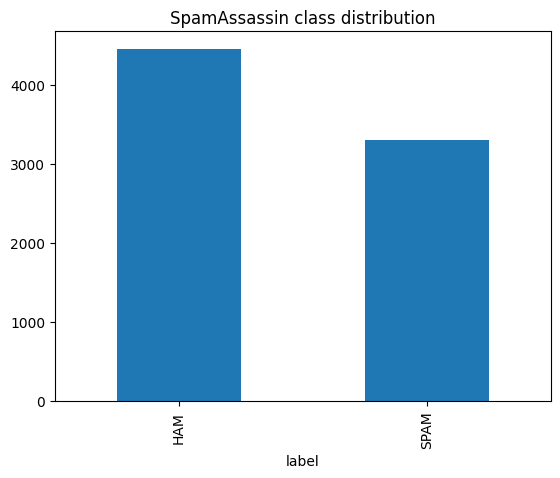

In [8]:
# Count of each class
print(spamassassin["label"].value_counts())

# Same thing as percentages
print()
print(spamassassin["label"].value_counts(normalize=True).round(3))

# Draw a bar chart
spamassassin["label"].value_counts().plot(kind="bar", title="SpamAssassin class distribution")
plt.show()

### Step 5: Check labels against the source archive
Each row says which SpamAssassin archive it came from (like `20021010_easy_ham`).
The archive name tells us if the email was meant to be ham or spam, so we can double-check our labels.
`hard_ham` = normal emails that were picked because they *look* like spam (tricky for a model).

In [9]:
# Each archive should contain only ONE label (a row with 0 in a column is fine)
pd.crosstab(spamassassin["source_archive"], spamassassin["label"])

label,HAM,SPAM
source_archive,,
20021010_easy_ham,2551,0
20021010_hard_ham,250,0
20021010_spam,0,501
20030228_easy_ham_2,1401,0
20030228_hard_ham,251,0
20030228_spam_2,0,1398
20050311_spam_2,0,1397


## Phase 3: Data quality checks

### Step 6: Missing and empty text

In [10]:
# isna().sum() counts empty (missing) values in each column
print("Missing values:")
print(spamassassin.isna().sum())

# Also check for text that only has spaces
print()
print("Empty/whitespace-only emails:", (spamassassin["email"].str.strip() == "").sum())

Missing values:
source_archive    0
filename          0
label             0
email             0
label_num         0
dtype: int64

Empty/whitespace-only emails: 0


### Step 7: Duplicates and conflicting labels
- **Duplicate** = the same email appears more than once.
- **Conflict** = the same email text appears with BOTH labels. A model can't learn from contradicting answers.

Note: `filename` repeats here (the 7 archives reuse the same file numbers), so it is **not** a unique ID. Don't use it to find duplicates.

In [11]:
print("Duplicate raw emails:", spamassassin["email"].duplicated().sum())
print("Duplicate filenames (expected, different archives reuse names):", spamassassin["filename"].duplicated().sum())

# For each unique email, count how many different labels it has
conflict = spamassassin.groupby("email")["label_num"].nunique()
print("Raw emails with conflicting labels:", (conflict > 1).sum())

Duplicate raw emails: 1435
Duplicate filenames (expected, different archives reuse names): 1399
Raw emails with conflicting labels: 0


### Step 7b: Do the archives overlap?
The 7 archives were collected at different times, and newer ones can **re-include** emails from older ones.
Let's see how many emails of each archive also appear in a different archive.
This matters a lot: if the same email is in both your training and test data, your model score will look better than it really is.

In [12]:
# For each archive, count how many of its raw emails ALSO exist in another archive
overlap = {}
for arch in spamassassin["source_archive"].unique():
    this_archive = spamassassin[spamassassin["source_archive"] == arch]["email"]
    other_archives = spamassassin[spamassassin["source_archive"] != arch]["email"]
    # isin() checks each email against the set of emails from the other archives
    overlap[arch] = this_archive.isin(set(other_archives)).sum()

pd.DataFrame({
    "rows": spamassassin["source_archive"].value_counts(),
    "also_in_other_archive": pd.Series(overlap),
})

,rows,also_in_other_archive
20021010_easy_ham,2551,0
20021010_hard_ham,250,16
20021010_spam,501,0
20030228_easy_ham_2,1401,0
20030228_hard_ham,251,14
20030228_spam_2,1398,1397
20050311_spam_2,1397,1397


**What to notice:** an archive where almost every row also appears elsewhere (for example `20050311_spam_2`) adds almost no new data.
We will remove these duplicates in the cleaning step, keeping one copy of each email.

## Phase 4: Look at the raw emails

### Step 8: Raw length statistics

In [13]:
# Work on a copy so the original table stays untouched
df = spamassassin.copy()

# Length of the RAW email (this includes all the headers)
df["raw_chars"] = df["email"].str.len()
df["raw_words"] = df["email"].str.split().str.len()

print(df[["raw_chars", "raw_words"]].describe())
print()
print(df.groupby("label")["raw_words"].describe())

           raw_chars     raw_words
count    7749.000000   7749.000000
mean     6181.389728    593.607820
std     10403.869152    793.914917
min       368.000000     45.000000
25%      2596.000000    268.000000
50%      3702.000000    382.000000
75%      5638.000000    581.000000
max    300734.000000  15172.000000

        count        mean         std   min    25%    50%    75%      max
label                                                                    
HAM    4453.0  592.406243  826.711549  45.0  279.0  374.0  533.0  15172.0
SPAM   3296.0  595.231189  747.444405  77.0  253.0  397.0  651.0  11857.0


### Step 9: Read one raw email
Look at how much of the start is headers (`Received:`, `Return-Path:`, `X-Mailer:` ...) and how little is the real message.

In [14]:
# repr-style printing is not needed here; just print the first 1500 characters
print(df["email"].iloc[0][:1500])

From fork-admin@xent.com  Wed Aug 28 10:50:29 2002
Return-Path: <fork-admin@xent.com>
Delivered-To: yyyy@localhost.netnoteinc.com
Received: from localhost (localhost [127.0.0.1])
	by phobos.labs.netnoteinc.com (Postfix) with ESMTP id CBC6A44156
	for <jm@localhost>; Wed, 28 Aug 2002 05:50:08 -0400 (EDT)
Received: from phobos [127.0.0.1]
	by localhost with IMAP (fetchmail-5.9.0)
	for jm@localhost (single-drop); Wed, 28 Aug 2002 10:50:08 +0100 (IST)
Received: from xent.com ([64.161.22.236]) by dogma.slashnull.org
    (8.11.6/8.11.6) with ESMTP id g7RLFhZ26129 for <jm@jmason.org>;
    Tue, 27 Aug 2002 22:15:43 +0100
Received: from lair.xent.com (localhost [127.0.0.1]) by xent.com (Postfix)
    with ESMTP id AE7E42940D8; Tue, 27 Aug 2002 14:13:09 -0700 (PDT)
Delivered-To: fork@example.com
Received: from mail.evergo.net (unknown [206.191.151.2]) by xent.com
    (Postfix) with SMTP id 94B3729409A for <fork@xent.com>; Tue,
    27 Aug 2002 14:12:25 -0700 (PDT)
Received: (qmail 2729 invoked from

### Step 10: Header leakage check (why we must remove headers)
If ham mostly comes from certain mailing lists/servers and spam from others,
a model can learn "this sender = ham" instead of learning what spam looks like.
That looks great on this data but fails on real emails. Let's see if it happens here.

In [15]:
# Pull the "From:" header out of each raw email using a simple pattern
# (?m) means "treat each line separately"; we grab the domain after the @ sign
df["sender_domain"] = df["email"].str.extract(r"(?im)^from:.*?@([\w\.-]+)")[0].str.lower()

print("Top sender domains in HAM:")
print(df[df["label"] == "HAM"]["sender_domain"].value_counts().head(8))
print()
print("Top sender domains in SPAM:")
print(df[df["label"] == "SPAM"]["sender_domain"].value_counts().head(8))

Top sender domains in HAM:
sender_domain
example.com              667
newsletter.online.com    170
hotmail.com               99
slack.net                 83
canada.com                82
perl.org                  78
egwn.net                  64
barrera.org               62
Name: count, dtype: int64

Top sender domains in SPAM:
sender_domain
hotmail.com          347
yahoo.com            298
aol.com              130
msn.com              120
insurancemail.net    104
btamail.net.cn        65
mail.com              58
excite.com            51
Name: count, dtype: int64


**What to notice:** if the top domains are very different between ham and spam, the headers would leak the answer.
So our final text will use **only the subject and the message body**, never the headers.

## Phase 5: Parse the emails (extract subject and body)

### Step 11: Write the parsing functions
Three small helpers:
1. `html_to_text` removes HTML tags (some emails are HTML only).
2. `get_text` reads the text of an email part. Some spam uses fake character encodings like `unknown-8bit`,
   which makes Python crash, so we fall back to a safe way of reading.
3. `parse_email` pulls out the subject and body from one raw email.

In [17]:
# --- Helper 1: remove HTML tags and keep only the visible text ---
class _HTMLStripper(HTMLParser):
    def __init__(self):
        super().__init__()
        self.parts = []        # collected pieces of text
        self.skip = False      # True while inside <script> or <style>
    def handle_starttag(self, tag, attrs):
        if tag in ("script", "style"):
            self.skip = True
    def handle_endtag(self, tag):
        if tag in ("script", "style"):
            self.skip = False
    def handle_data(self, data):
        if not self.skip:
            self.parts.append(data)

def html_to_text(html):
    stripper = _HTMLStripper()
    try:
        stripper.feed(html)
    except Exception:
        pass
    return " ".join(stripper.parts)

# --- Helper 2: read the text of one email part safely ---
def get_text(part):
    try:
        return part.get_content()
    except Exception:
        # Fallback for broken encodings: decode the raw bytes and replace bad characters
        payload = part.get_payload(decode=True)
        if payload is None:
            return ""
        return payload.decode("utf-8", errors="replace")

# --- Helper 3: parse one raw email into (subject, body) ---
def parse_email(raw):
    try:
        msg = email.message_from_string(raw, policy=policy.default)
        subject = str(msg.get("subject", "") or "")

        # Prefer the plain-text version of the message
        part = msg.get_body(preferencelist=("plain",))
        if part is not None:
            body = get_text(part)
        else:
            # No plain text: use the HTML version and strip the tags
            part = msg.get_body(preferencelist=("html",))
            body = html_to_text(get_text(part)) if part is not None else ""

        return subject, str(body)
    except Exception:
        # If parsing completely fails we return empty strings (we count these below)
        return "", ""

print("Functions ready.")

Functions ready.


### Step 12: Run the parser on every email
This takes about 15 to 30 seconds for ~7,700 emails.

In [18]:
# Apply parse_email to every raw email; result is a list of (subject, body) pairs
parsed = df["email"].apply(parse_email)

# Split the pairs into two new columns
df["subject"] = parsed.str[0]
df["body"] = parsed.str[1]

# How many ended up with NO body at all?
empty_body = df["body"].str.strip() == ""
print("Emails with empty body:", empty_body.sum())
print(df[empty_body].groupby("label").size())

Emails with empty body: 39
label
SPAM    39
dtype: int64


**Why do some emails have an empty body?** Some spam is just an image or an attachment with no text.
We will drop emails that have no usable text at all (no subject AND no body), since a model has nothing to learn from.

## Phase 6: EDA on the parsed text

### Step 13: New length statistics (before vs after)

In [19]:
# Combine subject and body, then count words
df["text_raw"] = (df["subject"] + " " + df["body"]).str.replace(r"\s+", " ", regex=True).str.strip()
df["parsed_words"] = df["text_raw"].str.split().str.len()

# Compare typical length before (raw email) and after (parsed text)
print("Median words BEFORE parsing:", int(df["raw_words"].median()))
print("Median words AFTER parsing :", int(df["parsed_words"].median()))
print()
print(df.groupby("label")["parsed_words"].describe())

Median words BEFORE parsing: 382
Median words AFTER parsing : 158

        count        mean         std  min    25%    50%     75%      max
label                                                                    
HAM    4453.0  309.973276  666.948870  8.0   83.0  156.0  288.00  14959.0
SPAM   3296.0  329.644114  669.388731  1.0  100.0  160.0  305.25  11625.0


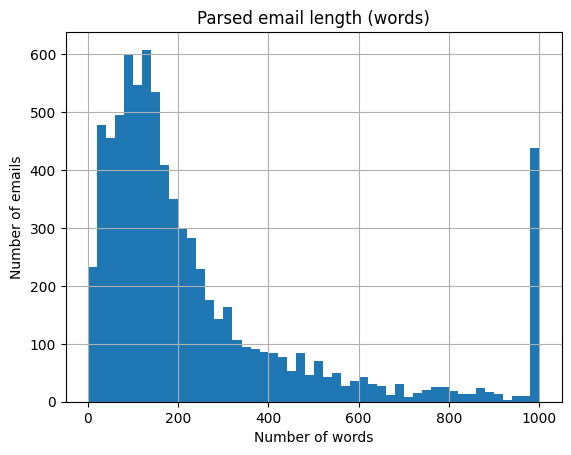

In [20]:
# Histogram of parsed email lengths
# clip(upper=1000) squashes very long emails to 1000 so the chart stays readable
df["parsed_words"].clip(upper=1000).hist(bins=50)
plt.title("Parsed email length (words)")
plt.xlabel("Number of words")
plt.ylabel("Number of emails")
plt.show()

### Step 14: Read real parsed examples
Never skip this. Compare with Step 9: now we only see the real message.

In [21]:
# Print 3 random ham and 3 random spam emails (first 400 characters only)
for lbl in ["HAM", "SPAM"]:
    print(f"\n===== {lbl} =====")
    samples = df[(df["label"] == lbl) & (df["parsed_words"] > 0)]["text_raw"].sample(3, random_state=1)
    for t in samples:
        print(t[:400])
        print("---")


===== HAM =====
Re: New testing packages BTW: I just a found a quite nice looking apt repositry for all kinds of audio apps at http://ccrma-www.stanford.edu/planetccrma/software/ Peter On Thu, 2002-09-19 at 23:28, Angles Puglisi wrote: > Matthias Saou (matthias@rpmforge.net) wrote*: > >- I've rebuilt a new "alsaplayer" package based on Angle's one. > > Cool, one less package to maintain :) > > One interesting thi
---
[IIU] Eircom aDSL Nat'ing Hi all, apologies for the possible silly question (i don't think it is, but), but is Eircom's aDSL service NAT'ed? and what implications would that have for VoIP? I know there are difficulties with VoIP or connecting to clients connected to a NAT'ed network from the internet wild (i.e. machines with static, real IPs) any help pointers would be helpful, cheers -- rgrds, Be
---
[Razor-users] Collision of hashes? The following was personal correspondence between two people. I can't fathom how Razor thinks it is spam: > > We are struggling with the d

### Step 15: Look for noise
This tells us what cleaning is really needed.

In [22]:
# Each check gives True/False per email. mean() turns that into a percentage.
# flags=re.M means "check every line", so ^> finds lines that START with ">"
checks = {
    "contains url":            df["text_raw"].str.contains(r"http|www", regex=True),
    "contains email address":  df["text_raw"].str.contains(r"\S+@\S+", regex=True),
    "contains html tags":      df["body"].str.contains(r"<[^>]+>", regex=True),
    "non-ascii characters":    df["text_raw"].str.contains(r"[^\x00-\x7f]", regex=True),
    "has quoted reply lines":  df["body"].str.contains(r"^>", regex=True, flags=re.M),
}

for name, mask in checks.items():
    print(f"{name:25s} {mask.mean():.1%}")

# Quoted reply lines (starting with ">") split by class
print()
print("Quoted reply lines by class:")
print(checks["has quoted reply lines"].groupby(df["label"]).mean().round(3))

contains url              73.3%
contains email address    55.7%
contains html tags        23.2%
non-ascii characters      14.0%
has quoted reply lines    29.2%

Quoted reply lines by class:
label
HAM     0.491
SPAM    0.022
Name: body, dtype: float64


**What to notice:** quoted lines (`> some old text`) appear in a large share of HAM but almost never in SPAM,
because ham comes from real mailing-list conversations with replies.
That is another leakage risk (the model could learn "has `>` lines = ham"), so we **remove quoted lines** in the cleaning step.

### Step 16: Most common words in ham vs spam (parsed text)

In [23]:
# Counter counts how many times each word appears
from collections import Counter

def top_words(series, n=15):
    # Lowercase, join all emails into one long string, split into words, count
    return Counter(" ".join(series).lower().split()).most_common(n)

print("HAM :", top_words(df[df["label"] == "HAM"]["text_raw"]))
print()
print("SPAM:", top_words(df[df["label"] == "SPAM"]["text_raw"]))

HAM : [('the', 55843), ('>', 37590), ('to', 33091), ('a', 25963), ('and', 24858), ('of', 24789), ('in', 16969), ('is', 14863), ('for', 13782), ('that', 12488), ('i', 11358), ('on', 10040), ('it', 9622), ('you', 9082), ('this', 8175)]

SPAM: [('the', 33393), ('to', 30705), ('and', 23118), ('of', 20018), ('you', 19941), ('a', 16447), ('your', 14487), ('for', 13343), ('in', 11971), ('is', 10714), ('this', 10417), ('with', 6597), ('on', 6561), ('or', 6545), ('are', 6482)]


## Phase 7: Preprocessing (cleaning)
We turn the parsed text into the final clean `email` column.
The style matches the Enron dataset (lowercase, no punctuation, starts with the word `subject`)
so all three datasets look the same when we combine them later.

### Step 17: Write the cleaning function

In [24]:
def clean_email(subject, body):
    # 1. Remove quoted reply lines (lines starting with ">")
    lines = [ln for ln in str(body).splitlines() if not ln.lstrip().startswith(">")]
    body = "\n".join(lines)

    # 2. Remove the "On Mon, 5 Aug ... wrote:" line that introduces a quote
    body = re.sub(r"(?im)^on .{0,200}wrote:\s*$", " ", body)

    # 3. Join subject and body, then make everything lowercase
    text = (str(subject) + " " + body).lower()

    # 4. Replace web links and email addresses with simple placeholder words
    #    (we keep the idea "there was a link" because that is useful for spam detection)
    text = re.sub(r"https?://\S+|www\.\S+", " url ", text)
    text = re.sub(r"\S+@\S+", " emailaddr ", text)

    # 5. Remove leftover HTML tags
    text = re.sub(r"<[^>]+>", " ", text)

    # 6. Keep only letters and numbers (remove punctuation and symbols)
    text = re.sub(r"[^a-z0-9\s]", " ", text)

    # 7. Collapse many spaces/newlines into a single space
    text = re.sub(r"\s+", " ", text).strip()
    return text

# Quick test on one email so we can see the result
i = df[df["parsed_words"] > 50].index[0]
print("BEFORE:", (df.loc[i, "subject"] + " " + df.loc[i, "body"])[:300].replace("\n", " "))
print()
print("AFTER :", clean_email(df.loc[i, "subject"], df.loc[i, "body"])[:300])

BEFORE: RE: The Curse of India's Socialism  > From: fork-admin@xent.com [mailto:fork-admin@xent.com] On Behalf Of James > Rogers  > Subject: Re: The Curse of India's Socialism >  > On Tue, 2002-08-20 at 15:01, Ian Andrew Bell wrote:  > > They > > finished their routine with the a quadruple lutz -- laying of

AFTER : re the curse of india s socialism james and further why focus on the fact they were laid off and not on the fact they were hired in the first place btw i saw someone claim that aside from the efficiency of the market there were also gains to society from irrational behavior if a society has business


### Step 18: Apply the cleaning to every email and filter

In [25]:
# Apply the cleaning function row by row
df["clean_text"] = [clean_email(s, b) for s, b in zip(df["subject"], df["body"])]
df["clean_words"] = df["clean_text"].str.split().str.len()

rows_start = len(df)

# 1. Remove emails with too little text left (fewer than 3 words = not useful)
#    Change the number 3 if you want a different cutoff
df = df[df["clean_words"] >= 3]
print("Removed (too short / empty):", rows_start - len(df))

# 2. Check for conflicting labels AFTER cleaning (cleaning can make two different emails identical)
conflict = df.groupby("clean_text")["label_num"].nunique()
conflict_texts = conflict[conflict > 1].index
print("Texts with conflicting labels:", len(conflict_texts))
df = df[~df["clean_text"].isin(conflict_texts)]

# 3. Remove exact duplicate emails (keep the first copy)
before_dups = len(df)
df = df.drop_duplicates(subset="clean_text")
print("Removed duplicates:", before_dups - len(df))

print()
print("Rows before:", len(spamassassin), "| Rows after:", len(df))

Removed (too short / empty): 18
Texts with conflicting labels: 0
Removed duplicates: 1920

Rows before: 7749 | Rows after: 5811


### Step 19: Check the result after cleaning
Make sure the class balance is still reasonable and nothing broke.

**Expected:** some archives (like `20050311_spam_2`) can drop to **0 rows**. That is not a bug.
As Step 7b showed, their emails were already in an older archive, so only one copy is kept.
`20030228_hard_ham` also loses most of its rows: it has the same messages as `20021010_hard_ham`, but with slightly different headers,
so those copies only look identical **after** we strip the headers (Step 17).
Most of the duplicates were spam, so the balance shifts toward ham (about 70% ham / 30% spam).

In [26]:
# Class balance after cleaning
print(df["label"].value_counts())
print()
print(df["label"].value_counts(normalize=True).round(3))

# Which archives lost the most rows?
print()
before = spamassassin["source_archive"].value_counts()
after = df["source_archive"].value_counts().reindex(before.index, fill_value=0)
print(pd.DataFrame({"before": before, "after": after, "removed": before - after}))

label
HAM     4049
SPAM    1762
Name: count, dtype: int64

label
HAM     0.697
SPAM    0.303
Name: proportion, dtype: float64

                     before  after  removed
source_archive                             
20021010_easy_ham      2551   2407      144
20030228_easy_ham_2    1401   1389       12
20030228_spam_2        1398   1302       96
20050311_spam_2        1397      0     1397
20021010_spam           501    460       41
20030228_hard_ham       251     24      227
20021010_hard_ham       250    229       21


In [27]:
# Length of the cleaned text by class
print(df.groupby("label")["clean_words"].describe())

# Very long emails: how many have more than 1000 words?
print()
print("Emails with more than 1000 words:", (df["clean_words"] > 1000).sum())

        count        mean         std  min   25%    50%    75%      max
label                                                                  
HAM    4049.0  225.529513  579.266332  8.0  55.0  100.0  190.0  14760.0
SPAM   1762.0  335.464813  702.026685  3.0  99.0  160.0  296.0  11753.0

Emails with more than 1000 words: 253


**Note on very long emails:** we keep them for now so the saved dataset stays flexible.
When you build the ML model, you can truncate each email to a fixed length (for example the first 500 to 1000 words).

## Phase 8: Standardize and save

### Step 20: Build the final two-column dataset
We add the word `subject` at the start (same style as Enron), keep only `email` and `label`,
and rename so all 3 datasets match later.

In [28]:
spamassassin_final = pd.DataFrame({
    "email": "subject " + df["clean_text"],     # same style as the Enron dataset
    "label": df["label_num"].astype(int),        # 0 = ham, 1 = spam
}).reset_index(drop=True)                        # reset_index gives clean row numbers 0,1,2...

print("Final shape:", spamassassin_final.shape)
print(spamassassin_final["label"].value_counts())
spamassassin_final.head()

Final shape: (5811, 2)
label
0    4049
1    1762
Name: count, dtype: int64


,email,label
0,subject re the curse of india s socialism jame...,0
1,subject re arrrghhh had gpg working now it doe...,0
2,subject re bad focus click behaviours for a lo...,0
3,subject re alsa almost made easy ah the mixer ...,0
4,subject creating rpms with subdirs install com...,0


### Step 21: Final sanity checks

In [29]:
# Nothing should be missing
print("Missing values:", spamassassin_final.isna().sum().to_dict())

# No duplicate emails should be left
print("Duplicate emails:", spamassassin_final["email"].duplicated().sum())

# Only labels 0 and 1 should exist
print("Unique labels:", sorted(spamassassin_final["label"].unique()))

# Read 2 random cleaned emails one more time
for t in spamassassin_final["email"].sample(2, random_state=3):
    print()
    print(t[:300])

Missing values: {'email': 0, 'label': 0}
Duplicate emails: 0
Unique labels: [np.int64(0), np.int64(1)]

subject free for you qwof fire your boss say goodbye to the 9 5 tired of working to make someone else wealthy free tape teaches you how to make you wealthy click here and send your name and mailing address for a free copy to unsubscribe click here ndmcshjjevibsvurgdvmldytkkogshjm

subject re gabber packages for 8 0 was all set for red hat linux 8 0 once upon a time matthias wrote well i ve made an updated libsigc 1 0 4 package it rebuilds cleanly on 7 3 but the so libraries are missing when trying to rebuild on 8 0 the a and la files and everything else is though do you have 


### Step 22: Save to a CSV file

In [30]:
# Create the "processed" folder if it does not exist yet
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)

# index=False means "don't write the row numbers into the file"
spamassassin_final.to_csv(OUT_PATH, index=False)
print("Saved:", OUT_PATH)

Saved: ../data/processed/spamassassin_clean.csv


## Done with SpamAssassin

Next: do the same for the **Synthetic** dataset, then combine the three clean files
(`enron_clean.csv`, `spamassassin_clean.csv`, and the synthetic one) into one final ML-ready dataset.